# Observed heat and cold at a weather station

Fit return levels for the hottest and coldest day of the year at Chicago O'Hare
(NOAA GHCNh station **USW00094846**, 2000–2024), with an explicit audit of which
years are complete. A station record complements gridded reanalysis and
CRC Open's projections. The headless twin is
[`pipelines/noaa_isd_pipeline.py`](../../pipelines/noaa_isd_pipeline.py).

crc-sdk reads GHCNh's hourly reports and reduces them to the **annual maximum
daily maximum** and **annual minimum daily minimum temperature**. A day counts
only with reports in all 24 hours; a year counts only when at least 90% of its
days are complete. Values are sampled hourly temperatures, not instrument daily
TXx/TNn. The pipeline also accepts `source="isd"` (NOAA's older Integrated
Surface Database, frozen since August 2025), but ISD hourly reads currently fail
in crc-sdk, so this notebook uses GHCNh.

Run from a crc-docs checkout (`uv sync --locked`, then `uv run jupyter lab`).
The first run downloads one hourly file per station-year; later runs reuse the
cache.

In [1]:
#@title Install dependencies and prepare this notebook
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--pre",
                           "--disable-pip-version-check", "crc-sdk>=1.0.0a2,<2", "plotly>=6"])
ROOT = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines/noaa_isd_pipeline.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow.parquet as pq
from IPython.display import display

from pipelines.noaa_isd_pipeline import run

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470

## Read, reduce and fit

`run` writes the annual values for each tail (`heat_annual.parquet`,
`cold_annual.parquet`) before fitting, so they can be inspected on their own.
Each tail is then fitted explicitly: GEV by L-moments, with a Gumbel fallback
(Gumbel for maxima on heat, for minima on cold), and at least
`minimum_years` usable years per station. Heat uses the upper tail
(`q = 1 − 1/T`); cold uses the lower tail (`q = 1/T`).

In [2]:
OUTPUT = Path("pipeline_output/noaa_ghcnh")
START, END = 2000, 2024
summary = run(["USW00094846"], OUTPUT, source="ghcnh", start=START, end=END,
              minimum_years=20, minimum_coverage=0.9)
display(pd.DataFrame(summary["tails"]).T[["annual_values", "usable_years", "incomplete_years",
                                           "station_supports", "fit_failures", "diagnostics"]])

,annual_values,usable_years,incomplete_years,station_supports,fit_failures,diagnostics
heat,25,23,2,1,{},"[incomplete_days, incomplete_years]"
cold,25,23,2,1,{},"[incomplete_days, incomplete_years]"


## Audit the years before trusting the fit

Incomplete years keep a row with a null value, the reason and the actual
coverage; they never enter the fit silently.

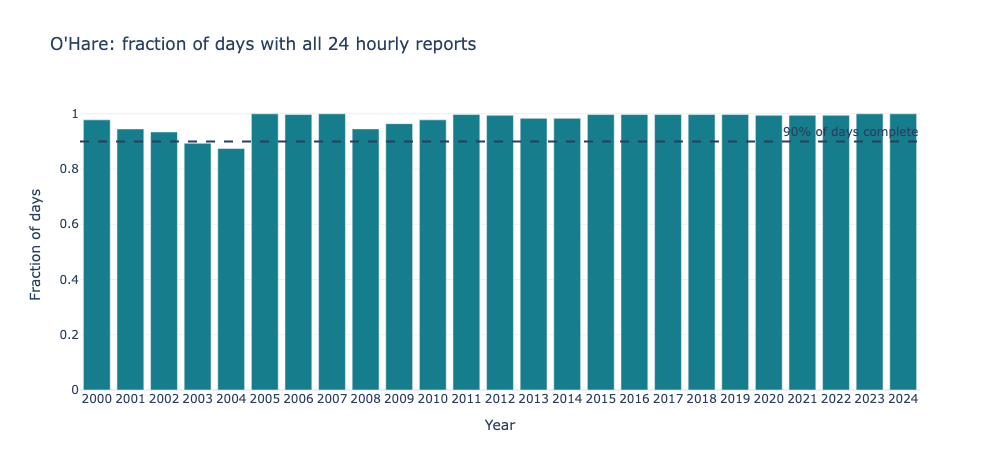

Years left out: {'2003': '326 of 365 expected valid observations; required fraction 0.9', '2004': '320 of 366 expected valid observations; required fraction 0.9'}


In [3]:
annual = {tail: pq.read_table(OUTPUT / f"{tail}_annual.parquet").to_pandas() for tail in ("heat", "cold")}
heat = annual["heat"]
fraction = heat.coverage.map(lambda c: c["valid"] / c["expected"] if c else None)
fig = go.Figure(go.Bar(x=heat.time, y=fraction,
                       marker_color=["#167d8d" if v is not None else "#c44e52" for v in heat.value]))
fig.add_hline(y=0.9, line_dash="dash", annotation_text="90% of days complete")
fig.update_layout(title="O'Hare: fraction of days with all 24 hourly reports",
                  xaxis_title="Year", yaxis_title="Fraction of days", yaxis_range=[0, 1.05])
fig.show()
missing = heat[heat.value.isna()]
print("Years left out:", dict(zip(missing.time, missing.failure.map(lambda f: f["message"]))) or "none")

## Annual extremes and fitted return levels

Dots are the annual values at their empirical return periods (Weibull plotting
positions); lines are the fitted return levels. Return periods beyond the
25-year record are extrapolations.

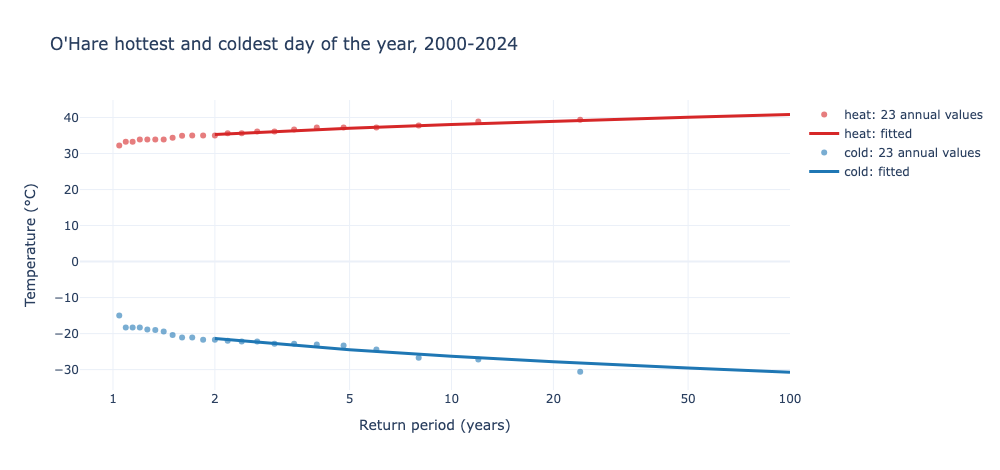

tail,cold,heat
return_period_years,,
2.0,-21.4,35.3
5.0,-24.5,37.0
10.0,-26.3,38.1
20.0,-27.8,39.0
50.0,-29.5,40.1
100.0,-30.7,40.8


In [4]:
levels = pq.read_table(summary["return_levels"]).to_pandas()
fig = go.Figure()
for tail, color in (("heat", "#d62728"), ("cold", "#1f77b4")):
    values = annual[tail].value.dropna().sort_values(ascending=(tail == "cold")).to_numpy()
    periods = (len(values) + 1) / pd.Series(range(1, len(values) + 1))
    fig.add_trace(go.Scatter(x=periods, y=values, mode="markers", marker=dict(color=color, opacity=0.6),
                             name=f"{tail}: {len(values)} annual values"))
    fitted = levels[levels["tail"] == tail]
    fig.add_trace(go.Scatter(x=fitted.return_period_years, y=fitted.temperature, mode="lines",
                             line=dict(color=color, width=3), name=f"{tail}: fitted"))
fig.update_layout(title=f"O'Hare hottest and coldest day of the year, {START}-{END}",
                  xaxis=dict(title="Return period (years)", type="log", tickvals=[1, 2, 5, 10, 20, 50, 100]),
                  yaxis_title="Temperature (°C)")
fig.show()
display(levels.pivot(index="return_period_years", columns="tail", values="temperature").round(1))

## Limits and reuse

- **A station is a point.** It does not represent nearby assets or an H3 cell's
  whole area, and instruments, siting and reporting practices change over time.
- **Stationarity.** The fit assumes the 2000–2024 climate is one population; a
  warming trend means it understates future heat extremes and overstates future
  cold ones.
- **Long return periods are extrapolations** of 25 annual values.

Headless runs, including a box instead of station IDs:

```sh
uv run python pipelines/noaa_isd_pipeline.py --source ghcnh --stations USW00094846
uv run python pipelines/noaa_isd_pipeline.py --source ghcnh --bounds -87.94 41.95 -87.92 41.97
```